# Lab 10-02 · MOSFET DC Operation and Biasing

Companion to [chapter 10-02](../../chapters/10-02-mosfet-dc-operation-and-biasing.md). Predict before each run; the `assert` lines check results against the answer keys.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, fsolve

def ids(vgs, vds, k, vt, lam=0.0):
    vov = vgs - vt
    if vov <= 0:
        return 0.0
    if vds < vov:
        return k * (vov * vds - vds**2 / 2)
    return 0.5 * k * vov**2 * (1 + lam * vds)

## Part 1 · Regions and load lines

*Predict first:* in Example 10-02.1 ($V_{GS}$ = 1 V, $k_n$ = 2 mA/V², 3.3 V supply), at what $R_D$ does the transistor leave saturation?

edge of saturation at R_D = 11.2 kOhm


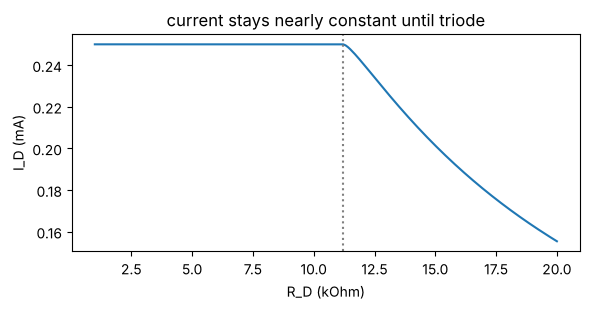

In [2]:
rds = np.linspace(1e3, 20e3, 200)
vd = [brentq(lambda x: ids(1.0, x, 2e-3, 0.5) - (3.3 - x) / r, 0, 3.3) for r in rds]
idd = [(3.3 - x) / r * 1e3 for x, r in zip(vd, rds)]
edge = brentq(lambda r: 3.3 - r * 0.25e-3 - 0.5, 1e3, 2e4)
print(f"edge of saturation at R_D = {edge/1e3:.1f} kOhm")
assert abs(edge / 1e3 - 11.2) < 0.05
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(rds / 1e3, idd); ax.axvline(edge / 1e3, ls=":", color="0.5")
ax.set_xlabel("R_D (kOhm)"); ax.set_ylabel("I_D (mA)"); ax.set_title("current stays nearly constant until triode")
plt.tight_layout(); plt.show()

## Part 2 · Bias Monte Carlo

*Predict first:* with σ = 25 mV of threshold spread, the spread of $I_D$ for (i) a fixed $V_{GS}$ = 1.151 V, (ii) the divider with $R_S$ = 1 kΩ of Example 10-02.3, (iii) the 10 kΩ current reference of Example 10-02.5.

fixed V_GS        : mean 0.8502 mA, sigma 7.56%
divider + R_S     : mean 0.8489 mA, sigma 2.13%
current reference : mean 0.2450 mA, sigma 0.95%


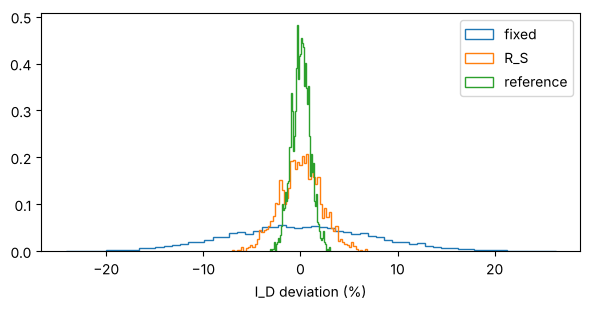

In [3]:
rng = np.random.default_rng(1002)
dvt = rng.normal(0, 0.025, 10000)
vgs3 = 2.0 - brentq(lambda x: ids(2.0 - x, 5, 4e-3, 0.5) * 1e3 - x, 0, 2)
def deg(vt):
    return brentq(lambda x: ids(2.0 - x, 5, 4e-3, vt) * 1e3 - x, 0, 2) / 1e3
def ref(vt):
    v = brentq(lambda x: (3.3 - x) / 10e3 - ids(x, x, 4e-3, vt), vt, 3.3)
    return (3.3 - v) / 10e3
fixed = np.array([ids(vgs3, 5, 4e-3, 0.5 + d) for d in dvt])
dg = np.array([deg(0.5 + d) for d in dvt[:2000]])
rf = np.array([ref(0.5 + d) for d in dvt[:2000]])
for name, x in (("fixed V_GS", fixed), ("divider + R_S", dg), ("current reference", rf)):
    print(f"{name:18s}: mean {x.mean()*1e3:.4f} mA, sigma {x.std()/x.mean()*100:.2f}%")
assert abs(fixed.std() / fixed.mean() * 100 - 7.56) < 0.005
assert abs(dg.std() / dg.mean() * 100 - 2.13) < 0.005
assert abs(rf.std() / rf.mean() * 100 - 0.95) < 0.005
plt.figure(figsize=(6, 3.2))
for name, x in (("fixed", fixed), ("R_S", dg), ("reference", rf)):
    plt.hist((x / x.mean() - 1) * 100, bins=60, histtype="step", density=True, label=name)
plt.xlabel("I_D deviation (%)"); plt.legend(); plt.tight_layout(); plt.show()

## Part 3 · Switch resistance against gate drive

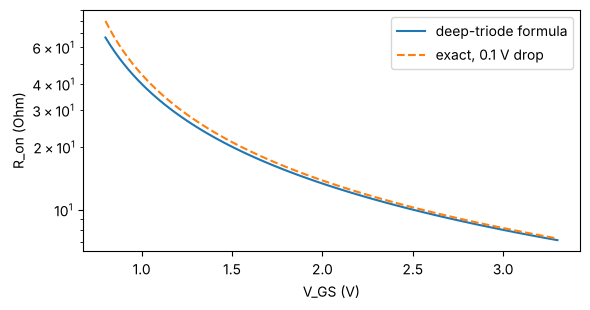

exact over formula at 1.8 V: 4.0%


In [4]:
vg = np.linspace(0.8, 3.3, 100)
r_formula = 1 / (50e-3 * (vg - 0.5))
r_exact = [0.1 / ids(x, 0.1, 50e-3, 0.5) for x in vg]
plt.figure(figsize=(6, 3.2))
plt.plot(vg, r_formula, label="deep-triode formula"); plt.plot(vg, r_exact, "--", label="exact, 0.1 V drop")
plt.yscale("log"); plt.xlabel("V_GS (V)"); plt.ylabel("R_on (Ohm)"); plt.legend(); plt.tight_layout(); plt.show()
excess = (0.1 / ids(1.8, 0.1, 50e-3, 0.5)) * (50e-3 * 1.3) - 1
print(f"exact over formula at 1.8 V: {excess*100:.1f}%")
assert abs(excess * 100 - 4.0) < 0.05

## Part 4 · Body effect by iteration

In [5]:
def vt_of(vs): return 0.5 + 0.4 * (math.sqrt(0.7 + vs) - math.sqrt(0.7))
x = 0.0
for i in range(6):
    vt = vt_of(x)
    x = brentq(lambda s: ids(2.5 - s, 10, 2e-3, vt) * 2e3 - s, 0, 2.5 - vt)
    print(f"pass {i+1}: V_S = {x:.5f} V")
vs, vt = fsolve(lambda y: [y[1] - vt_of(y[0]), ids(2.5 - y[0], 10, 2e-3, y[1]) * 2e3 - y[0]], [1, 0.6])
print(f"root finder: V_S = {vs:.5f} V, V_TN = {vt:.4f} V, I_D = {vs/2e3*1e3:.4f} mA")
assert abs(vs - 1.071) < 5e-4 and abs(vs / 2e3 * 1e3 - 0.535) < 5e-4

pass 1: V_S = 1.21922 V
pass 2: V_S = 1.05443 V
pass 3: V_S = 1.07254 V
pass 4: V_S = 1.07051 V
pass 5: V_S = 1.07073 V
pass 6: V_S = 1.07071 V
root finder: V_S = 1.07071 V, V_TN = 0.6976 V, I_D = 0.5354 mA
